# 02 — Feature Engineering, Baselines & Random Forest

Picks up from `01_data_cleaning_and_eda.ipynb`. Here we:
1. Build calendar, lag and rolling features **without leaking the target** (rolling features use only past hours).
2. Split chronologically into **train 70% / validation 10% / test 20%**. Validation is used later to calibrate the anomaly threshold; test is only used to report results.
3. Compare the Random Forest against **simple baselines** (persistence and seasonal naive). A model is only useful if it beats these.
4. Train two forecasters: **1 hour ahead** and **day ahead**.

## 2.1 Load the cleaned hourly data

In [6]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

IN_DIR = "/kaggle/input/notebooks/azizullahasad/01-data-cleaning-and-eda" 
WORK_DIR = "/kaggle/working/"   

hourly = pd.read_csv(f"{IN_DIR}/house38_hourly_clean.csv", index_col=0, parse_dates=True)
print(hourly.shape)
hourly.head()

(8393, 7)


,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW),observed
datetime,,,,,,,
2023-09-02 12:00:00,0.526868,0.003235,0.004568,0.005349,0.153806,0.002909,True
2023-09-02 13:00:00,1.298505,0.004410,0.004978,0.004553,0.239058,0.002941,True
2023-09-02 14:00:00,1.857305,0.004286,0.004638,0.002990,0.205566,0.036126,True
2023-09-02 15:00:00,1.619104,0.002441,0.002962,0.002348,0.254719,0.001775,True
2023-09-02 16:00:00,1.593942,0.003102,0.002518,0.004691,0.225510,0.003807,True


## 2.2 Feature engineering

- **Calendar:** `hour`, `dow` (day of week), `is_weekend`. (We do *not* use `month`: with one year of data the test months never appear in training.)
- **Lags:** usage 1, 2, 24, 48 and 168 hours ago.
- **Rolling features:** mean and std of the last 24 hours, mean of the last 168 hours.

**Important:** the rolling features are computed on `shift(1)`, i.e. on past hours only. A plain `rolling(24).mean()` would include the current hour — the very value we want to predict — and leak the answer into the features.

In [7]:
LAGS = [1, 2, 24, 48, 168]
BASE_FEATURES = (["hour", "dow", "is_weekend"] + [f"lag_{l}" for l in LAGS]
                 + ["roll_mean_24", "roll_std_24", "roll_mean_168"])
DAY_AHEAD = ["hour", "dow", "is_weekend", "lag_24", "lag_48", "lag_168"]   # only info known a day earlier

d = hourly.copy()
s = d["Usage (kW)"]

d["hour"] = d.index.hour
d["dow"] = d.index.dayofweek
d["is_weekend"] = (d["dow"] >= 5).astype(int)

for lag in LAGS:
    d[f"lag_{lag}"] = s.shift(lag)

past = s.shift(1)                                  # <- only past values
d["roll_mean_24"] = past.rolling(24).mean()
d["roll_std_24"] = past.rolling(24).std()
d["roll_mean_168"] = past.rolling(168).mean()

d["y"] = s                                         # the value we want to predict
d.head()

,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW),observed,hour,dow,is_weekend,lag_1,lag_2,lag_24,lag_48,lag_168,roll_mean_24,roll_std_24,roll_mean_168,y
datetime,,,,,,,,,,,,,,,,,,,
2023-09-02 12:00:00,0.526868,0.003235,0.004568,0.005349,0.153806,0.002909,True,12,5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.526868
2023-09-02 13:00:00,1.298505,0.004410,0.004978,0.004553,0.239058,0.002941,True,13,5,1,0.526868,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.298505
2023-09-02 14:00:00,1.857305,0.004286,0.004638,0.002990,0.205566,0.036126,True,14,5,1,1.298505,0.526868,NaN,NaN,NaN,NaN,NaN,NaN,1.857305
2023-09-02 15:00:00,1.619104,0.002441,0.002962,0.002348,0.254719,0.001775,True,15,5,1,1.857305,1.298505,NaN,NaN,NaN,NaN,NaN,NaN,1.619104
2023-09-02 16:00:00,1.593942,0.003102,0.002518,0.004691,0.225510,0.003807,True,16,5,1,1.619104,1.857305,NaN,NaN,NaN,NaN,NaN,NaN,1.593942


## 2.3 Chronological train / validation / test split

Time-series data must never be split randomly (that would leak the future into training). We also keep only rows that are **real measured hours** (`observed`) with complete features, so filled values are never used as targets.

In [8]:
d = d.dropna(subset=BASE_FEATURES + ["y"])         # drop rows inside long gaps
d = d[d["observed"]]                               # only real measured hours

n = len(d)
train = d.iloc[: int(0.7 * n)]
val = d.iloc[int(0.7 * n): int(0.8 * n)]
test = d.iloc[int(0.8 * n):]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(part):5d} hours | {part.index.min().date()} -> {part.index.max().date()}")

train:  5756 hours | 2023-09-09 -> 2024-05-06
val  :   823 hours | 2024-05-06 -> 2024-06-09
test :  1645 hours | 2024-06-09 -> 2024-08-17


## 2.4 Metrics and baselines

- **MAE / RMSE** in kW; **sMAPE** is a bounded percentage error (plain MAPE explodes near zero usage).
- **Skill score** = `1 - MAE_model / MAE_naive24`. `0` = no better than "same hour yesterday", `> 0` = better, `< 0` = worse.

Baselines (no learning at all):
- **Persistence:** the next hour equals the last hour (`lag_1`).
- **Seasonal naive 24h:** the next hour equals the same hour yesterday (`lag_24`).
- **Seasonal naive 168h:** same hour last week (`lag_168`).

In [9]:
def smape(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return 100 * np.mean(2 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8))


def scores(y_true, y_pred):
    return {"MAE (kW)": mean_absolute_error(y_true, y_pred),
            "RMSE (kW)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "sMAPE (%)": smape(y_true, y_pred)}


def make_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                 n_jobs=-1, random_state=42)


y_test = test["y"]
results = {
    "Persistence (t-1h)": scores(y_test, test["lag_1"]),
    "Seasonal naive (t-24h)": scores(y_test, test["lag_24"]),
    "Seasonal naive (t-168h)": scores(y_test, test["lag_168"]),
}

## 2.5 Random Forest — 1 hour ahead

We train two versions:
- **Plain RF:** predicts the usage level directly. (Used later for anomaly detection.)
- **Delta RF:** predicts the *change* from the last hour (`y - lag_1`) and adds `lag_1` back. The model only has to learn the change, which is usually easier and more accurate.

In [10]:
# Plain Random Forest
rf_plain = make_rf()
rf_plain.fit(train[BASE_FEATURES], train["y"])
pred_plain = rf_plain.predict(test[BASE_FEATURES])
results["Random Forest (plain)"] = scores(y_test, pred_plain)

# Delta Random Forest: learn (y - lag_1), then add lag_1 back
rf_delta = make_rf()
rf_delta.fit(train[BASE_FEATURES], train["y"] - train["lag_1"])
pred_delta = test["lag_1"].values + rf_delta.predict(test[BASE_FEATURES])
results["Random Forest (delta, 1h)"] = scores(y_test, pred_delta)

table_1h = pd.DataFrame(results).T
table_1h["Skill vs naive-24h"] = 1 - table_1h["MAE (kW)"] / table_1h.loc["Seasonal naive (t-24h)", "MAE (kW)"]
print(f"All models scored on the same {len(test)} test hours")
table_1h.sort_values("MAE (kW)").round(4)

All models scored on the same 1645 test hours


,MAE (kW),RMSE (kW),sMAPE (%),Skill vs naive-24h
Persistence (t-1h),0.2691,0.5043,28.2380,0.3340
"Random Forest (delta, 1h)",0.2892,0.4945,38.2482,0.2841
Random Forest (plain),0.3389,0.5996,41.1305,0.1613
Seasonal naive (t-24h),0.4040,0.6875,51.5118,0.0000
Seasonal naive (t-168h),0.5691,0.9267,64.5978,-0.4085


## 2.6 Day-ahead forecast

For a day-ahead forecast we may only use information that is known 24 hours earlier, so the features are limited to the calendar and `lag_24`, `lag_48`, `lag_168`. The delta model learns `y - lag_24` and is compared with "same hour yesterday".

In [11]:
rf_24 = make_rf()
rf_24.fit(train[DAY_AHEAD], train["y"] - train["lag_24"])
pred_24 = test["lag_24"].values + rf_24.predict(test[DAY_AHEAD])

day_ahead = {
    "Seasonal naive (t-24h)": scores(y_test, test["lag_24"]),
    "Random Forest (delta, day-ahead)": scores(y_test, pred_24),
}
table_24 = pd.DataFrame(day_ahead).T
table_24["Skill vs naive-24h"] = 1 - table_24["MAE (kW)"] / table_24.loc["Seasonal naive (t-24h)", "MAE (kW)"]
table_24.round(4)

,MAE (kW),RMSE (kW),sMAPE (%),Skill vs naive-24h
Seasonal naive (t-24h),0.4040,0.6875,51.5118,0.0000
"Random Forest (delta, day-ahead)",0.3863,0.6326,48.5635,0.0439


## 2.7 Feature importance and a visual check

roll_mean_24     0.2729
lag_1            0.2289
roll_std_24      0.1267
lag_24           0.0891
roll_mean_168    0.0768
lag_48           0.0661
lag_168          0.0609
hour             0.0356
lag_2            0.0318
dow              0.0093
is_weekend       0.0020
dtype: float64


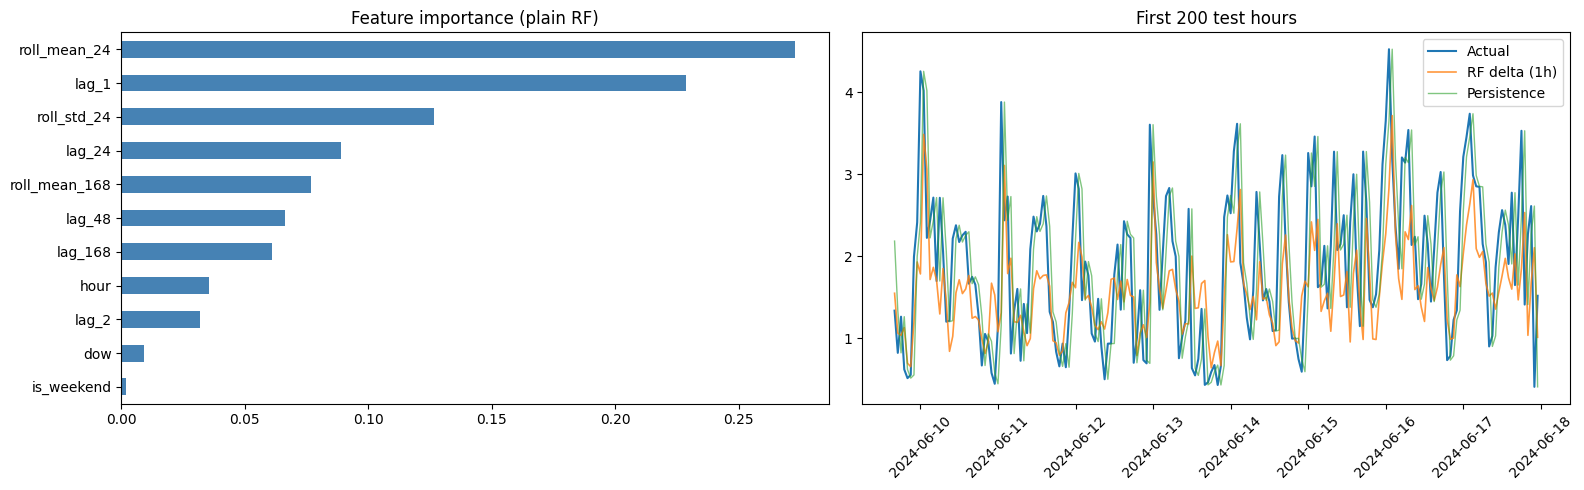

In [12]:
importance = pd.Series(rf_plain.feature_importances_, index=BASE_FEATURES).sort_values(ascending=False)
print(importance.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

importance.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Feature importance (plain RF)")

axes[1].plot(test.index[:200], y_test.values[:200], label="Actual", linewidth=1.5)
axes[1].plot(test.index[:200], pred_delta[:200], label="RF delta (1h)", linewidth=1.2, alpha=0.8)
axes[1].plot(test.index[:200], test["lag_1"].values[:200], label="Persistence", linewidth=1, alpha=0.6)
axes[1].set_title("First 200 test hours")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [13]:
best_ml = table_1h.loc[["Random Forest (plain)", "Random Forest (delta, 1h)"], "MAE (kW)"].idxmin()
best_all = table_1h["MAE (kW)"].idxmin()
print("Best 1-hour model on MAE:", best_all)
print("Best Random Forest variant:", best_ml)
print("Day-ahead skill vs seasonal naive:", round(table_24.loc["Random Forest (delta, day-ahead)", "Skill vs naive-24h"], 3))

Best 1-hour model on MAE: Persistence (t-1h)
Best Random Forest variant: Random Forest (delta, 1h)
Day-ahead skill vs seasonal naive: 0.044


### Takeaway

- The Random Forest follows the daily rhythm well, but lag-based models under-predict sudden spikes (e.g. an AC suddenly switching on).
- **At 1 hour ahead, persistence is a very strong baseline** — the last hour already tells you most of what the next hour will be. Read the table above honestly: a model that does not beat persistence on MAE is not adding value at that horizon, although it can still win on RMSE (large errors) or be useful at longer horizons.
- At **day-ahead**, the delta Random Forest should beat "same hour yesterday" (positive skill score).
- Plain RF vs delta RF: the delta version learns the change instead of the level.

**Next notebook:** `03_lstm_deep_learning_models.ipynb`

## 2.8 Save everything the next notebooks need

In [14]:
train.to_csv(f"{WORK_DIR}/house38_train.csv")
val.to_csv(f"{WORK_DIR}/house38_val.csv")
test.to_csv(f"{WORK_DIR}/house38_test.csv")

# each model is saved together with its feature list and the lag it is built on
joblib.dump({"model": rf_plain, "features": BASE_FEATURES, "base": None}, f"{WORK_DIR}/rf_plain_1h.pkl", compress=3)
joblib.dump({"model": rf_delta, "features": BASE_FEATURES, "base": "lag_1"}, f"{WORK_DIR}/rf_delta_1h.pkl", compress=3)
joblib.dump({"model": rf_24, "features": DAY_AHEAD, "base": "lag_24"}, f"{WORK_DIR}/rf_delta_24h.pkl", compress=3)

with open(f"{WORK_DIR}/model_config.json", "w") as f:
    json.dump({"base_features": BASE_FEATURES, "day_ahead_features": DAY_AHEAD, "lags": LAGS,
               "split": {"train": 0.7, "val": 0.1, "test": 0.2}}, f, indent=2)

print("Saved: train/val/test CSVs, rf_plain_1h.pkl, rf_delta_1h.pkl, rf_delta_24h.pkl, model_config.json")

Saved: train/val/test CSVs, rf_plain_1h.pkl, rf_delta_1h.pkl, rf_delta_24h.pkl, model_config.json
